
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [1]:
import os
import numpy as np
import pandas as pd

data_path = ['..', '..', '..', 'datasets']
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath)

print('размер:', data.shape)
print(data.dtypes.value_counts())

размер: (10299, 562)
float64    561
str          1
Name: count, dtype: int64


In [2]:
# колонок 562, поэтому pandas показывает только первые и последние
# чтобы посмотреть все: pd.set_option('display.max_columns', None)
data.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [3]:
print('пропущенных значений:', data.isna().sum().sum())

# 561 числовой признак и одна текстовая колонка Activity, это класс (6 видов активности)
data['Activity'].value_counts()

пропущенных значений: 0


Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

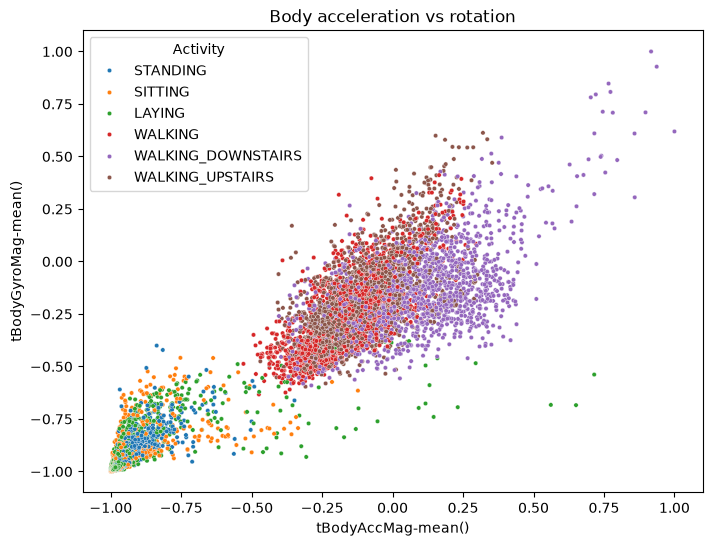

корреляция: 0.956


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# модуль ускорения тела и модуль скорости вращения: чем сильнее движение, тем больше оба
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='tBodyAccMag-mean()', y='tBodyGyroMag-mean()', hue='Activity', s=10)
plt.title('Body acceleration vs rotation')
plt.show()

print('корреляция:', round(data['tBodyAccMag-mean()'].corr(data['tBodyGyroMag-mean()']), 3))

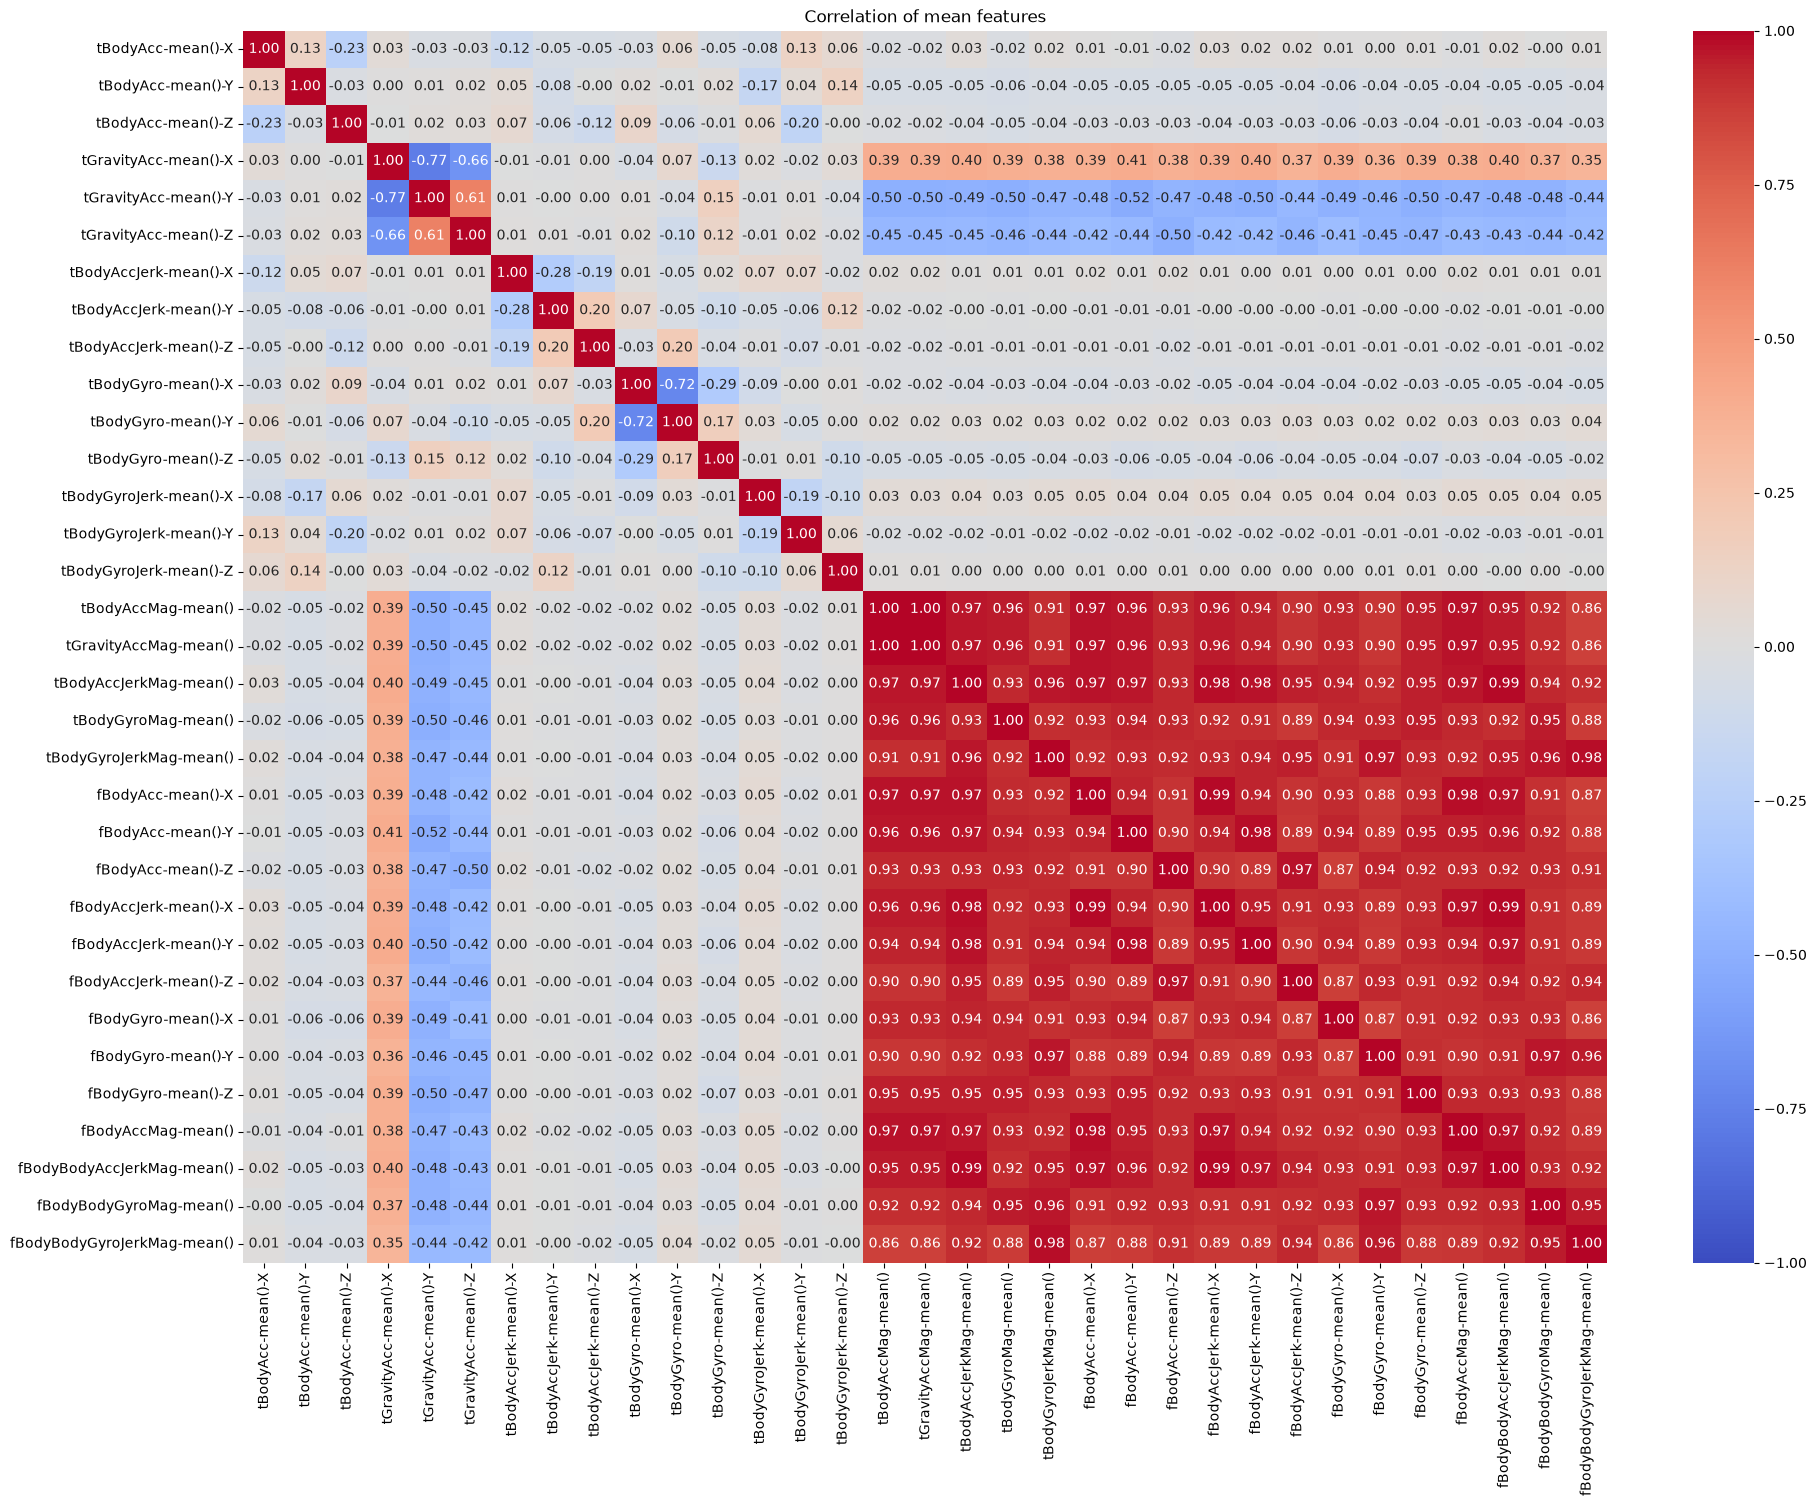

In [5]:
# 561 признак на одной карте не прочитать, поэтому берем все средние значения (-mean())
cols = [c for c in data.columns if '-mean()' in c]
corr = data[cols].corr()

plt.figure(figsize=(22, 16))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of mean features')
plt.show()

# Видно три группы. Модули и частотные признаки сильно связаны между собой (от 0.86 до 1): при движении растут все сигналы
# Средние по осям для ускорения и вращения тела с этим блоком почти не связаны (|r| не больше 0.07)
# Гравитация по X связана с Y и Z отрицательно (-0.77 и -0.66), это положение телефона
# tGravityAccMag-mean() точная копия tBodyAccMag-mean(), поэтому у них корреляция ровно 1

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

# Activity - это класс, а для регрессии нужна числовая цель
# поэтому предсказываем признак tBodyAcc-mean()-X  (среднее ускорение тела по оси X)
# по остальным 560 признакам
target = 'tBodyAcc-mean()-X'
X_reg = data.drop(columns=['Activity', target])
y_reg = data[target]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

lr_model = LinearRegression()
lr_model.fit(X_train_r, y_train_r)
pred_train = lr_model.predict(X_train_r)
pred_test = lr_model.predict(X_test_r)

score_list = list()
for name, y_true, y_pred in [('train', y_train_r, pred_train), ('test', y_test_r, pred_test)]:
    mse = mean_squared_error(y_true, y_pred)
    score_list.append((name, mean_absolute_error(y_true, y_pred), mse, np.sqrt(mse)))

display(pd.DataFrame(score_list, columns=['data', 'MAE', 'MSE', 'RMSE']))
print('для сравнения, std цели на train:', round(y_train_r.std(), 4))
print('для сравнения, std цели на test:', round(y_test_r.std(), 4))

# На train ошибки меньше, чем на test (RMSE 0.029 против 0.039), значит модель немного переобучается
# MAE на test выросла меньше, чем RMSE, значит на test есть отдельные сильные промахи, а RMSE их сильнее штрафует
# RMSE на test (0.039) меньше std цели (0.070), значит модель лучше, чем если всегда предсказывать среднее

,data,MAE,MSE,RMSE
0,train,0.020662,0.000860,0.029321
1,test,0.023176,0.001547,0.039331


для сравнения, std цели на train: 0.0669
для сравнения, std цели на test: 0.0704



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [7]:
import sklearn
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

print('scikit-learn', sklearn.__version__)

X = data.drop(columns='Activity')
y = data['Activity']
# stratify, чтобы доли видов активности в train и test были одинаковые
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# признаки уже нормированы в [-1, 1], поэтому KNN можно без масштабирования
knn = KNeighborsClassifier() # по умолчанию k = 5
scores = cross_val_score(knn, X_train, y_train, cv=5)
print('accuracy по fold-ам:', scores.round(3))
print('средняя accuracy:', round(scores.mean(), 4), '+-', round(scores.std(), 4))

scikit-learn 1.9.1
accuracy по fold-ам: [0.968 0.964 0.966 0.966 0.965]
средняя accuracy: 0.9659 +- 0.0016


лучший k по accuracy: 1 | выбранный k (устойчивее к шуму): 5


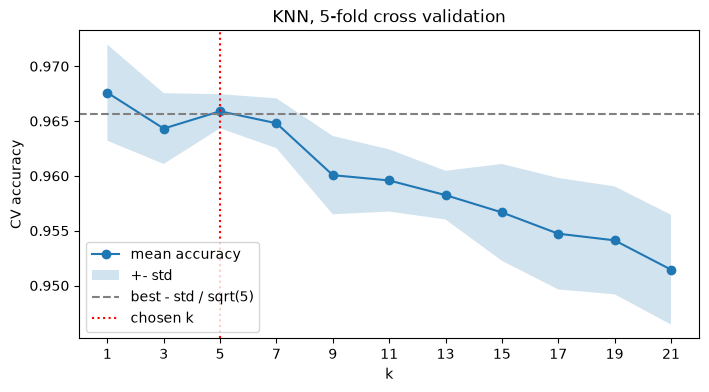

In [8]:
# а теперь кросс-валидацией выбираем k: для каждого k средняя accuracy по 5 fold-ам, test не трогаем
# k нечетные, чтобы реже были ничьи при голосовании
score_list = list()
for k in range(1, 22, 2):
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5)
    score_list.append((k, scores.mean(), scores.std()))

score_df = pd.DataFrame(score_list, columns=['k', 'accuracy', 'std'])

# k от 1 до 7 почти одинаковые, поэтому берем правило одной стандартной ошибки: среди k, которые хуже
# лучшего не больше чем на std / sqrt(5), выбираем самый большой, такая модель устойчивее к шуму
best = score_df.loc[score_df['accuracy'].idxmax()]
threshold = best['accuracy'] - best['std'] / np.sqrt(5)
best_k = score_df.loc[score_df['accuracy'] >= threshold, 'k'].max()
print('лучший k по accuracy:', int(best['k']), '| выбранный k (устойчивее к шуму):', best_k)

# полоса это разброс accuracy по fold-ам (+- std): у соседних k полосы сильно перекрываются,
# поэтому разница между ними в пределах шума. Выбранный k это самый большой k, у которого точка выше пунктира
ax = score_df.set_index('k')['accuracy'].plot(marker='o', figsize=(8, 4), label='mean accuracy')
ax.fill_between(score_df['k'], score_df['accuracy'] - score_df['std'], score_df['accuracy'] + score_df['std'], alpha=0.2, label='+- std')
ax.axhline(threshold, color='gray', linestyle='--', label='best - std / sqrt(5)')
ax.axvline(best_k, color='red', linestyle=':', label='chosen k')
ax.set(xlabel='k', ylabel='CV accuracy', title='KNN, 5-fold cross validation')
ax.set_xticks(range(1, 22, 2))
ax.legend(loc='lower left');

In [9]:
# одна проверка на отдельном test
# test используем только сейчас, когда k уже выбран
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
print('accuracy на test:', round(knn_best.score(X_test, y_test), 4))

# С ростом k accuracy падает: соседей берется слишком много, и граница между классами размывается
# Accuracy на test (0.965) почти совпадает с оценкой кросс-валидации для k = 5 (0.966)

accuracy на test: 0.9646



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [10]:
from sklearn.metrics import r2_score
from sklearn.linear_model import RidgeCV

# линейная регрессия из раздела 3 и для сравнения Ridge (L2 регуляризация), alpha подбирает RidgeCV по кросс-валидации
print("Линейная регрессия:")
ridge = RidgeCV(alphas=np.logspace(-2, 3, 11))
ridge.fit(X_train_r, y_train_r)
print('alpha, выбранный RidgeCV:', ridge.alpha_)

score_list = list()
for name, model in [('Linear', lr_model), ('Ridge', ridge)]:
    pred_test = model.predict(X_test_r)
    mse = mean_squared_error(y_test_r, pred_test)
    score_list.append((name, mean_absolute_error(y_test_r, pred_test), mse, np.sqrt(mse),
                       r2_score(y_test_r, pred_test), r2_score(y_train_r, model.predict(X_train_r))))

pd.DataFrame(score_list, columns=['model', 'MAE', 'MSE', 'RMSE', 'R2 test', 'R2 train'])

# RidgeCV выбрал самый маленький alpha из сетки (0.01), и метрики почти не изменились (R2 на test 0.687 и 0.688)
# Разница между train и test (0.81 и 0.69) остается и с Ridge, то есть дело не в больших коэффициентах,
# и регуляризация здесь не нужна: строк намного больше, чем признаков (8239 и 560)

Линейная регрессия:
alpha, выбранный RidgeCV: 0.01


,model,MAE,MSE,RMSE,R2 test,R2 train
0,Linear,0.023176,0.001547,0.039331,0.688032,0.807938
1,Ridge,0.023274,0.001552,0.039393,0.687047,0.806569


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# бинарная задача: SITTING против STANDING, эти два класса различить труднее всего (это видно и в матрице ошибок ниже)
print("Логистическая регрессия:")
pair = data['Activity'].isin(['SITTING', 'STANDING'])
X_bin = data.loc[pair].drop(columns='Activity')
y_bin = (data.loc[pair, 'Activity'] == 'STANDING').astype(int)

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_bin, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

# max_iter больше, чем по умолчанию, иначе на 561 признаке модель не успевает сойтись
log_bin = LogisticRegression(max_iter=1000)
log_bin.fit(X_train_b, y_train_b)
pred_b = log_bin.predict(X_test_b)
# для ROC-AUC нужна вероятность класса 1 (STANDING), а не готовый ответ
proba_b = log_bin.predict_proba(X_test_b)[:, 1]
print('accuracy:', round(accuracy_score(y_test_b, pred_b), 4))
print('precision:', round(precision_score(y_test_b, pred_b), 4))
print('recall:', round(recall_score(y_test_b, pred_b), 4))
print('f1:', round(f1_score(y_test_b, pred_b), 4))
print('ROC-AUC:', round(roc_auc_score(y_test_b, proba_b), 4))

# Регуляризация тут уже есть: LogisticRegression в sklearn по умолчанию использует L2 с C=1
# Класс 1 это STANDING. Recall (0.961) выше precision (0.939), значит модель чаще называет сидящего стоящим, чем наоборот

Логистическая регрессия:
accuracy: 0.9471
precision: 0.9385
recall: 0.9606
f1: 0.9494
ROC-AUC: 0.9877


In [12]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# SVM с RBF ядром (по умолчанию) на всех 6 видах активности, split из раздела 4
# Регуляризация у SVC тоже есть, это параметр C (по умолчанию 1)
print("классификация по SVM:")
svm = SVC()
svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)
print('accuracy SVM:', round(accuracy_score(y_test, pred_svm), 4))
# precision, recall и f1 для каждого класса, macro avg это простое среднее по классам
print(classification_report(y_test, pred_svm, digits=3))

# хуже всего SITTING и STANDING (f1 0.939 и 0.943), остальные классы почти без ошибок

классификация по SVM:
accuracy SVM: 0.9757
                    precision    recall  f1-score   support

            LAYING      1.000     1.000     1.000       389
           SITTING      0.931     0.947     0.939       356
          STANDING      0.952     0.934     0.943       381
           WALKING      0.997     0.997     0.997       344
WALKING_DOWNSTAIRS      0.993     0.993     0.993       281
  WALKING_UPSTAIRS      0.987     0.990     0.989       309

          accuracy                          0.976      2060
         macro avg      0.977     0.977     0.977      2060
      weighted avg      0.976     0.976     0.976      2060



In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

# подбираем параметры SVM через GridSearchCV. Pipeline: сначала scaler, потом SVM,
# scaler внутри pipeline учится только на train части каждого fold
# В сетке есть и выбор scaler: 'passthrough' значит без масштабирования (признаки и так в [-1, 1])
print("подбор параметров SVM:")
pipe = Pipeline([('scaler', 'passthrough'), ('svm', SVC())])
params = {
    'scaler': ['passthrough', StandardScaler()],
    # C это обратная сила регуляризации: чем больше C, тем слабее регуляризация
    'svm__C': [1, 10, 100],
    # gamma задает ширину RBF ядра (чем больше gamma, тем уже ядро), 'scale' это значение по умолчанию
    'svm__gamma': ['scale', 0.01],
}
grid_svm = GridSearchCV(pipe, params, cv=5, n_jobs=-1)
grid_svm.fit(X_train, y_train)
print('лучшие параметры:', grid_svm.best_params_)
print('accuracy на кросс-валидации:', round(grid_svm.best_score_, 4))

# лучшая accuracy на кросс-валидации с scaler и без
res = pd.DataFrame(grid_svm.cv_results_)
res['scaler'] = res['param_scaler'].astype(str)
print(res.groupby('scaler')['mean_test_score'].max().round(4))

подбор параметров SVM:


лучшие параметры: {'scaler': 'passthrough', 'svm__C': 100, 'svm__gamma': 0.01}
accuracy на кросс-валидации: 0.9896
scaler
StandardScaler()    0.9852
passthrough         0.9896
Name: mean_test_score, dtype: float64


In [14]:
pred_grid = grid_svm.predict(X_test)
print('accuracy SVM после подбора:', round(accuracy_score(y_test, pred_grid), 4))
print(classification_report(y_test, pred_grid, digits=3))

# Подбор параметров заметно помог: accuracy на test выросла с 0.976 (SVC по умолчанию) до 0.993,
# а SITTING и STANDING теперь путаются гораздо реже (f1 0.979 и 0.982 вместо 0.939 и 0.943)
# Лучшее C = 100, то есть регуляризацию лучше ослабить. Scaler не нужен: признаки уже нормированы,
# а со StandardScaler на кросс-валидации даже хуже (0.985 против 0.990)

accuracy SVM после подбора: 0.9927
                    precision    recall  f1-score   support

            LAYING      1.000     1.000     1.000       389
           SITTING      0.978     0.980     0.979       356
          STANDING      0.984     0.979     0.982       381
           WALKING      1.000     1.000     1.000       344
WALKING_DOWNSTAIRS      1.000     1.000     1.000       281
  WALKING_UPSTAIRS      0.997     1.000     0.998       309

          accuracy                          0.993      2060
         macro avg      0.993     0.993     0.993      2060
      weighted avg      0.993     0.993     0.993      2060



## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

accuracy: 0.9864


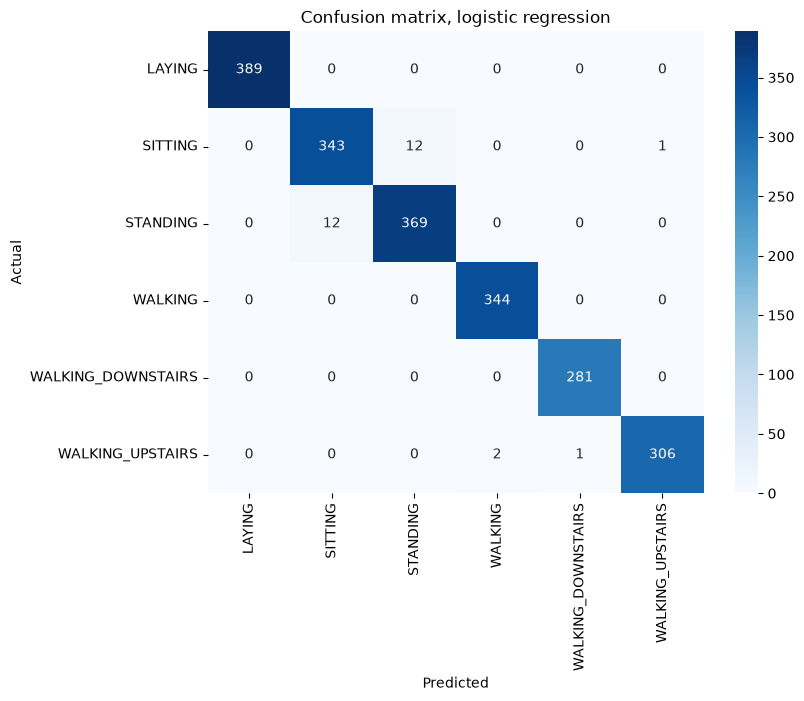

In [15]:
from sklearn.metrics import confusion_matrix

log_multi = LogisticRegression(max_iter=1000)
log_multi.fit(X_train, y_train)
y_pred = log_multi.predict(X_test)
print('accuracy:', round(accuracy_score(y_test, y_pred), 4))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix, logistic regression')
plt.show()

# из 2060 объектов test ошибок всего 28, и 24 из них это путаница SITTING и STANDING:
# по датчикам телефона сидеть и стоять почти одинаково. LAYING и ходьба определяются почти без ошибок


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

In [16]:
# J(theta) = (theta * x - y)**2, усредняем по точкам подмножества
# x это tBodyAccMag-mean(), y это tBodyGyroMag-mean() (та же пара, что на графике в разделе 2)
sub = data.sample(400, random_state=42)
x = sub['tBodyAccMag-mean()'].to_numpy()
y_gd = sub['tBodyGyroMag-mean()'].to_numpy()

def cost(theta):
    return np.mean((theta * x - y_gd) ** 2)

# производная J по theta равна 2 * mean((theta * x - y) * x)
# шаг должен быть меньше 1 / mean(x**2), здесь это примерно 1.9, иначе спуск разойдется
theta = 0.0
alpha = 0.3
history = []
thetas = []
for i in range(50):
    grad = 2 * np.mean((theta * x - y_gd) * x)
    theta = theta - alpha * grad
    thetas.append(theta)
    history.append(cost(theta))

# для проверки: у этой функции есть точное решение theta = sum(x * y) / sum(x**2)
theta_exact = np.sum(x * y_gd) / np.sum(x ** 2)
print('theta после спуска:', round(theta, 5), '| J:', round(cost(theta), 5))
print('точное решение theta:', round(theta_exact, 5), '| J:', round(cost(theta_exact), 5))


# первая итерация, на которой theta отличается от точного решения меньше чем на 1e-4
for i, t in enumerate(thetas):
    if abs(t - theta_exact) < 1e-4:
        reached = i + 1
        break
print('точное решение достигнуто на итерации', reached)

theta после спуска: 0.98096 | J: 0.0266
точное решение theta: 0.98096 | J: 0.0266
точное решение достигнуто на итерации 25


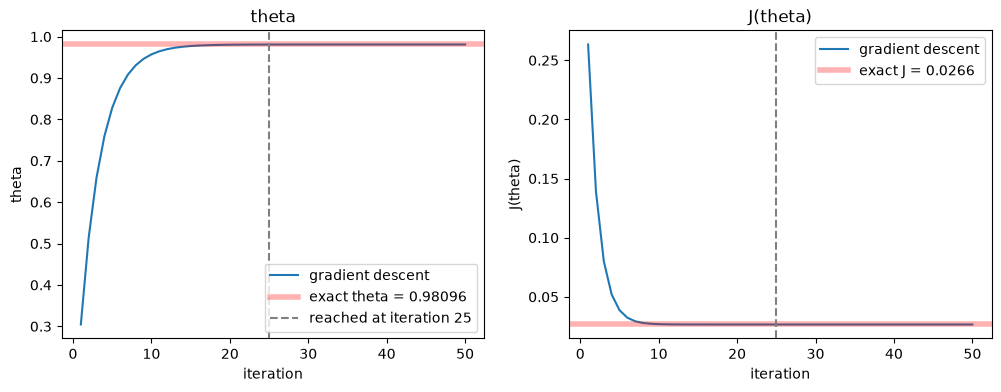

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
iterations = range(1, len(thetas) + 1)

# полупрозрачная красная линия это точное решение, пунктир это итерация, где спуск до него дошел
axes[0].plot(iterations, thetas, label='gradient descent')
axes[0].axhline(theta_exact, color='red', linewidth=4, alpha=0.3, label='exact theta = ' + str(round(theta_exact, 5)))
axes[0].axvline(reached, color='gray', linestyle='--', label='reached at iteration ' + str(reached))
axes[0].set(xlabel='iteration', ylabel='theta', title='theta')
axes[0].legend()

axes[1].plot(iterations, history, label='gradient descent')
axes[1].axhline(cost(theta_exact), color='red', linewidth=4, alpha=0.3, label='exact J = ' + str(round(cost(theta_exact), 5)))
axes[1].axvline(reached, color='gray', linestyle='--')
axes[1].set(xlabel='iteration', ylabel='J(theta)', title='J(theta)')
axes[1].legend()
plt.show()

# J выходит на минимум раньше, чем theta (примерно за 10 итераций), потому что J зависит от квадрата ошибки theta.
# theta с точностью 1e-4 совпадает с точным решением на 25 итерации

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Классификация по RandomForestClassifier:
accuracy: 0.9816
precision (macro): 0.9814
recall (macro): 0.9815
f1 (macro): 0.9814
ROC-AUC: 0.9996
Десять самых важных признаков для классификации:


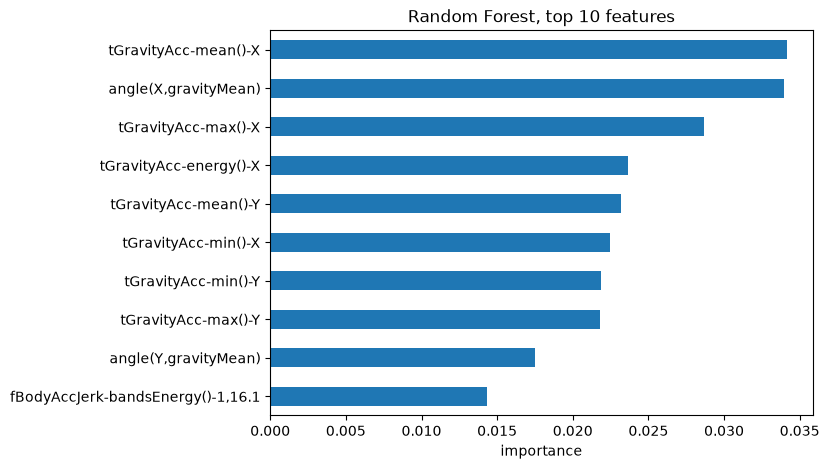

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

print("Классификация по RandomForestClassifier:")
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
# для 6 классов precision, recall и f1 усредняем по классам (macro), ROC-AUC считаем каждый класс против остальных (ovr)
print('accuracy:', round(accuracy_score(y_test, pred_rf), 4))
print('precision (macro):', round(precision_score(y_test, pred_rf, average='macro'), 4))
print('recall (macro):', round(recall_score(y_test, pred_rf, average='macro'), 4))
print('f1 (macro):', round(f1_score(y_test, pred_rf, average='macro'), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, rf.predict_proba(X_test), multi_class='ovr'), 4))

print("Десять самых важных признаков для классификации:")
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).plot.barh(figsize=(7, 5))
plt.gca().invert_yaxis()
plt.xlabel('importance')
plt.title('Random Forest, top 10 features')
plt.show()

# macro метрики почти равны accuracy (0.981), потому что классы сбалансированы и ошибок мало
# 9 из 10 самых важных признаков связаны с гравитацией (tGravityAcc и angle с gravityMean), то есть
# с положением телефона в пространстве, а оно сильно отличается, например, у LAYING

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Random Forest для регрессии: та же цель и тот же split, что в разделе 3, сравниваем с линейной регрессией
print("Регрессия по RandomForestRegressor:")
rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_reg.fit(X_train_r, y_train_r)

score_list = list()
for name, model in [('Linear', lr_model), ('Random Forest', rf_reg)]:
    pred_test = model.predict(X_test_r)
    mse = mean_squared_error(y_test_r, pred_test)
    score_list.append((name, mean_absolute_error(y_test_r, pred_test), mse, np.sqrt(mse),
                       r2_score(y_test_r, pred_test), r2_score(y_train_r, model.predict(X_train_r))))

print(pd.DataFrame(score_list, columns=['model', 'MAE', 'MSE', 'RMSE', 'R2 test', 'R2 train']))

# пять самых важных признаков для регрессии
print("\nПять самых важных признаков для регрессии:")
print(pd.Series(rf_reg.feature_importances_, index=X_train_r.columns).sort_values(ascending=False).head(5).round(3))

# Лес лучше линейной регрессии по всем метрикам на test, сильнее всего по MAE (0.013 против 0.023)
# RMSE улучшился мало (0.038 против 0.039): большинство точек лес предсказывает точнее, но отдельные сильные промахи остаются
# R2 на train (0.975) намного выше, чем на test (0.711): лес сильно подстраивается под train, это для него обычно
# Самый важный признак angle(tBodyAccMean,gravity) это угол между средним ускорением тела и гравитацией
# то есть он посчитан почти из той же величины, что и цель

Регрессия по RandomForestRegressor:
           model       MAE       MSE      RMSE   R2 test  R2 train
0         Linear  0.023176  0.001547  0.039331  0.688032  0.807938
1  Random Forest  0.013203  0.001432  0.037847  0.711128  0.974876

Пять самых важных признаков для регрессии:
angle(tBodyAccMean,gravity)    0.323
tGravityAcc-iqr()-X            0.181
tBodyAcc-entropy()-X           0.051
tGravityAcc-mad()-X            0.047
tBodyAcc-mean()-Y              0.041
dtype: float64


In [20]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# у AdaBoost по умолчанию базовая модель это пень (дерево глубины 1), для 6 классов он слишком слабый,
# поэтому добавим еще вариант с деревьями глубины 3
print("Классификация по AdaBoostClassifier и BaggingClassifier:")
models = {
    'AdaBoost, depth 1': AdaBoostClassifier(random_state=42),
    'AdaBoost, depth 3': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), random_state=42),
    'Bagging': BaggingClassifier(random_state=42, n_jobs=-1),
}

score_list = list()
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    # zero_division=0: если модель какой-то класс вообще не предсказывает, precision для него не определен, считаем его 0
    score_list.append((name, accuracy_score(y_test, pred),
                       precision_score(y_test, pred, average='macro', zero_division=0),
                       recall_score(y_test, pred, average='macro'),
                       f1_score(y_test, pred, average='macro'),
                       roc_auc_score(y_test, model.predict_proba(X_test), multi_class='ovr')))

pd.DataFrame(score_list, columns=['model', 'accuracy', 'precision', 'recall', 'f1', 'ROC-AUC'])

# AdaBoost с пнями почти не работает (accuracy 0.35), часть классов он вообще не предсказывает
# ROC-AUC у него при этом 0.918, потому что эта метрика смотрит на вероятности, а не на итоговый ответ
# С деревьями глубины 3 AdaBoost по accuracy и f1 немного лучше Bagging (0.962 и 0.958), а по ROC-AUC они почти равны
# Бустинг строит деревья по очереди, и каждое исправляет ошибки предыдущих, а Bagging строит их независимо и усредняет

Классификация по AdaBoostClassifier и BaggingClassifier:


,model,accuracy,precision,recall,f1,ROC-AUC
0,"AdaBoost, depth 1",0.350485,0.146856,0.331880,0.202442,0.917978
1,"AdaBoost, depth 3",0.961650,0.962787,0.963027,0.962713,0.997469
2,Bagging,0.958252,0.957798,0.957771,0.957763,0.998165


## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [21]:
from sklearn.ensemble import StackingClassifier

# мета-модель учится на предсказаниях базовых моделей, их StackingClassifier получает через кросс-валидацию (cv=5)
stack = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(random_state=42, n_jobs=-1)),
                ('svm', SVC(C=100, gamma=0.01)), # SVM с параметрами, подобранными в разделе 5
                ('lr', LogisticRegression(max_iter=1000))],
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1)
stack.fit(X_train, y_train)
pred_stack = stack.predict(X_test)
print('accuracy:', round(accuracy_score(y_test, pred_stack), 4))
print('precision (macro):', round(precision_score(y_test, pred_stack, average='macro'), 4))
print('recall (macro):', round(recall_score(y_test, pred_stack, average='macro'), 4))
print('f1 (macro):', round(f1_score(y_test, pred_stack, average='macro'), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, stack.predict_proba(X_test), multi_class='ovr'), 4))

# Stacking лучше каждой базовой модели: accuracy 0.9947 против 0.9927 у SVM после подбора,
# 0.9864 у логистической регрессии и 0.9816 у Random Forest. f1 (macro) 0.995, ROC-AUC почти 1

accuracy: 0.9947
precision (macro): 0.9949
recall (macro): 0.9951
f1 (macro): 0.995
ROC-AUC: 0.9999



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
